In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [12]:
# Load dataset
df = pd.read_csv('/content/sales_data_sample.csv',
                 encoding='latin1')

# Display first five rows
print("First 5 rows:")
print(df.head())

# Dataset information
print("\nDataset Information:")
print(df.info())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Dataset shape
print("\nDataset Shape:", df.shape)

# Number of unique customers
print("\nUnique Customers:",
      df['CUSTOMERNAME'].nunique())

First 5 rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye

In [13]:
# Convert ORDERDATE into datetime format
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'])

# Set reference date
reference_date = df['ORDERDATE'].max() + pd.Timedelta(days=1)

# Calculate RFM values customer-wise
rfm = df.groupby('CUSTOMERNAME').agg({

    'ORDERDATE': lambda x: (reference_date - x.max()).days,

    'ORDERNUMBER': 'nunique',

    'SALES': 'sum'

})

# Rename columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Display RFM dataset
print("Customer RFM Data:")
print(rfm.head())

print("\nRFM Shape:", rfm.shape)

Customer RFM Data:
                         Recency  Frequency   Monetary
CUSTOMERNAME                                          
AV Stores, Co.               196          3  157807.81
Alpha Cognac                  65          3   70488.44
Amica Models & Co.           265          2   94117.26
Anna's Decorations, Ltd       84          4  153996.13
Atelier graphique            188          3   24179.96

RFM Shape: (92, 3)


In [14]:
# Initialize StandardScaler
scaler = StandardScaler()

# Scale RFM features
scaled_data = scaler.fit_transform(rfm)

print("Feature Scaling Completed!")
print(scaled_data[:5])

Feature Scaling Completed!
[[ 0.10079171 -0.1158306   0.44443187]
 [-0.90147042 -0.1158306  -0.35149724]
 [ 0.62870077 -0.45958594 -0.13611702]
 [-0.75610415  0.22792473  0.40968783]
 [ 0.03958486 -0.1158306  -0.77360596]]


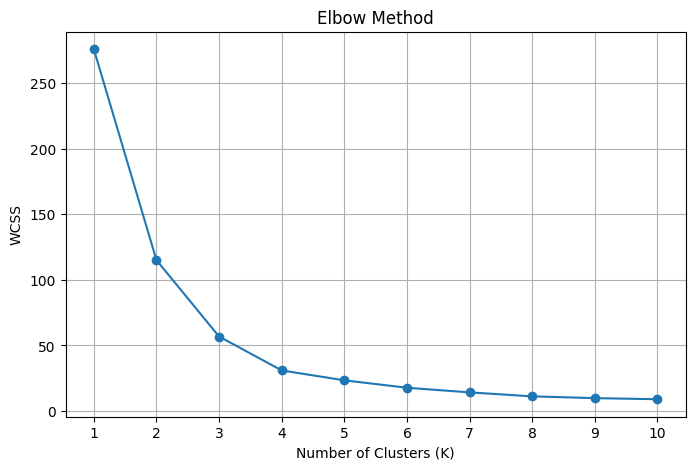

In [15]:
# Calculate WCSS for different K values
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    wcss.append(kmeans.inertia_)

# Plot Elbow graph
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [16]:
# Create KMeans model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
rfm['Cluster'] = kmeans.fit_predict(scaled_data)

print("K-Means Clustering Completed!")

print("\nCustomer Segments:")
print(rfm.head(10))

K-Means Clustering Completed!

Customer Segments:
                              Recency  Frequency   Monetary  Cluster
CUSTOMERNAME                                                        
AV Stores, Co.                    196          3  157807.81        3
Alpha Cognac                       65          3   70488.44        0
Amica Models & Co.                265          2   94117.26        3
Anna's Decorations, Ltd            84          4  153996.13        0
Atelier graphique                 188          3   24179.96        3
Australian Collectables, Ltd       23          3   64591.46        0
Australian Collectors, Co.        184          5  200995.41        3
Australian Gift Network, Co       119          3   59469.12        3
Auto Assoc. & Cie.                233          2   64834.32        3
Auto Canal Petit                   55          3   93170.66        0


In [17]:
score = silhouette_score(
    scaled_data,
    rfm['Cluster']
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.4945


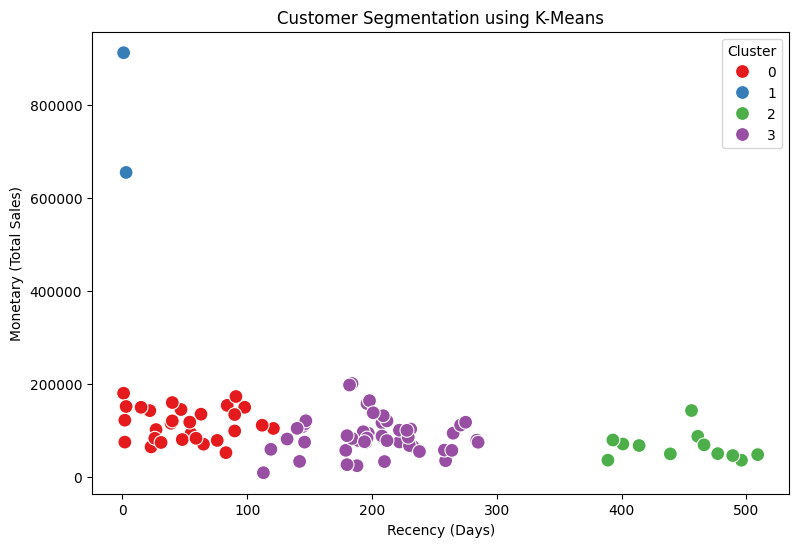

In [18]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x='Recency',
    y='Monetary',
    hue='Cluster',
    data=rfm,
    palette='Set1',
    s=100
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary (Total Sales)')

plt.show()

In [19]:
# Count customers in each cluster
print("Customers in Each Cluster:")
print(rfm['Cluster'].value_counts().sort_index())

# Calculate average RFM values for each cluster
cluster_analysis = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

print("\nCluster Analysis:")
print(cluster_analysis)

Customers in Each Cluster:
Cluster
0    29
1     2
2    12
3    49
Name: count, dtype: int64

Cluster Analysis:
         Recency  Frequency   Monetary
Cluster                               
0          51.97       3.52  114589.80
1           2.00      21.50  783576.08
2         449.17       2.08   65294.09
3         202.43       2.80   88955.99
